In [ ]:
from google.colab import drive
drive.mount('/content/drive', force_remount=True)


In [ ]:
!mkdir -p "/content/drive/MyDrive/unet_project/"


In [ ]:
!mv "/content/archive (6).zip" "/content/drive/MyDrive/unet_project/"


mv: cannot stat '/content/archive (6).zip': No such file or directory


In [ ]:
!ls "/content/drive/MyDrive/unet_project/"


'archive (6).zip'   dataset_full   fastsam_finetune	       sam_unet_runs
 dataset	    dataset_zip    fastsam_inference_visuals


In [ ]:
!unzip -o "/content/drive/MyDrive/unet_project/archive (6).zip" -d "/content/drive/MyDrive/unet_project/dataset/"


Streaming output truncated to the last 5000 lines.
  inflating: /content/drive/MyDrive/unet_project/dataset/Annotator 2 (bioinformatician)/Annotator 2 (bioinformatician)/Imagj_zips/Human_Mediastinum_02/0509-0295.roi  
  inflating: /content/drive/MyDrive/unet_project/dataset/Annotator 2 (bioinformatician)/Annotator 2 (bioinformatician)/Imagj_zips/Human_Mediastinum_02/0509-0479.roi  
  inflating: /content/drive/MyDrive/unet_project/dataset/Annotator 2 (bioinformatician)/Annotator 2 (bioinformatician)/Imagj_zips/Human_Mediastinum_03/0005-0219.roi  
  inflating: /content/drive/MyDrive/unet_project/dataset/Annotator 2 (bioinformatician)/Annotator 2 (bioinformatician)/Imagj_zips/Human_Mediastinum_03/0005-0454.roi  
  inflating: /content/drive/MyDrive/unet_project/dataset/Annotator 2 (bioinformatician)/Annotator 2 (bioinformatician)/Imagj_zips/Human_Mediastinum_03/0006-0164.roi  
  inflating: /content/drive/MyDrive/unet_project/dataset/Annotator 2 (bioinformatician)/Annotator 2 (bioinformatic

In [ ]:
from google.colab import files
uploaded = files.upload()


TypeError: 'NoneType' object is not subscriptable

In [ ]:
!ls /content


sample_data


In [ ]:
!mkdir -p "/content/drive/MyDrive/unet_project/dataset"


In [ ]:
!cp "/content/archive (9).zip" "/content/drive/MyDrive/unet_project/"


In [ ]:
!ls "/content/drive/MyDrive/unet_project/"


'archive (6).zip'   dataset	   dataset_zip	      fastsam_inference_visuals
'archive (9).zip'   dataset_full   fastsam_finetune   sam_unet_runs


In [ ]:
!unzip -o "/content/drive/MyDrive/unet_project/archive (9).zip" -d "/content/drive/MyDrive/unet_project/dataset/"


Streaming output truncated to the last 5000 lines.
  inflating: /content/drive/MyDrive/unet_project/dataset/Annotator 2 (bioinformatician)/Annotator 2 (bioinformatician)/Imagj_zips/Human_Mediastinum_02/0509-0295.roi  
  inflating: /content/drive/MyDrive/unet_project/dataset/Annotator 2 (bioinformatician)/Annotator 2 (bioinformatician)/Imagj_zips/Human_Mediastinum_02/0509-0479.roi  
  inflating: /content/drive/MyDrive/unet_project/dataset/Annotator 2 (bioinformatician)/Annotator 2 (bioinformatician)/Imagj_zips/Human_Mediastinum_03/0005-0219.roi  
  inflating: /content/drive/MyDrive/unet_project/dataset/Annotator 2 (bioinformatician)/Annotator 2 (bioinformatician)/Imagj_zips/Human_Mediastinum_03/0005-0454.roi  
  inflating: /content/drive/MyDrive/unet_project/dataset/Annotator 2 (bioinformatician)/Annotator 2 (bioinformatician)/Imagj_zips/Human_Mediastinum_03/0006-0164.roi  
  inflating: /content/drive/MyDrive/unet_project/dataset/Annotator 2 (bioinformatician)/Annotator 2 (bioinformatic

In [ ]:
!ls -R "/content/drive/MyDrive/unet_project/dataset/" | head -n 50


/content/drive/MyDrive/unet_project/dataset/:
Annotator 1 (biologist)
Annotator 1 (biologist second round of manual marks up)
Annotator 2 (bioinformatician)
images
masks
tissue images

/content/drive/MyDrive/unet_project/dataset/Annotator 1 (biologist):
distance maps
Imagj_zips
label masks
label masks modify
mask binary
mask binary without border
mask binary without border erode
overlay_save_path
weighted_maps
weighted_maps_erode

/content/drive/MyDrive/unet_project/dataset/Annotator 1 (biologist)/distance maps:
Human_AdrenalGland_01.png
Human_AdrenalGland_02.png
Human_AdrenalGland_03.png
Human_Larynx_01.png
Human_Larynx_02.png
Human_Larynx_03.png
Human_LymphNodes_01.png
Human_LymphNodes_02.png
Human_LymphNodes_03.png
Human_Mediastinum_01.png
Human_Mediastinum_02.png
Human_Mediastinum_03.png
Human_Pancreas_01.png
Human_Pancreas_02.png
Human_Pancreas_03.png
Human_Pleura_01.png
Human_Pleura_02.png
Human_Pleura_03.png
Human_Skin_01.png
Human_Skin_02.png
Human_Skin_03.png
Human_Testes_01.p

In [ ]:
import os, shutil, random
from pathlib import Path
from glob import glob

base = Path("/content/drive/MyDrive/unet_project/dataset")

# 1️⃣ Define source folders
src_images = base / "Annotator 1 (biologist)" / "distance maps"
src_masks  = base / "Annotator 1 (biologist)" / "mask binary"

# 2️⃣ Define target folders
tgt_images = base / "images"
tgt_masks  = base / "masks"

os.makedirs(tgt_images, exist_ok=True)
os.makedirs(tgt_masks, exist_ok=True)

# 3️⃣ Copy all images & masks
img_files = sorted(glob(str(src_images / "*.png")))
msk_files = sorted(glob(str(src_masks / "*.png")))

for img in img_files:
    shutil.copy(img, tgt_images / os.path.basename(img))
for msk in msk_files:
    shutil.copy(msk, tgt_masks / os.path.basename(msk))

print(f"✅ Copied {len(img_files)} images and {len(msk_files)} masks.")

# 4️⃣ Create train/val splits
for d in ['images/train','images/val','masks/train','masks/val']:
    os.makedirs(base / d, exist_ok=True)

pairs = list(zip(sorted(glob(str(tgt_images / "*.png"))), sorted(glob(str(tgt_masks / "*.png")))))
random.shuffle(pairs)
split = int(0.8 * len(pairs))
train_pairs, val_pairs = pairs[:split], pairs[split:]

for img, msk in train_pairs:
    shutil.copy(img, base / "images/train" / os.path.basename(img))
    shutil.copy(msk, base / "masks/train" / os.path.basename(msk))
for img, msk in val_pairs:
    shutil.copy(img, base / "images/val" / os.path.basename(img))
    shutil.copy(msk, base / "masks/val" / os.path.basename(msk))

print(f"✅ Split complete: {len(train_pairs)} train / {len(val_pairs)} val images.")


In [ ]:
!ls /content/drive/MyDrive/unet_project/dataset/images/train | head
!ls /content/drive/MyDrive/unet_project/dataset/masks/train | head


Human_AdrenalGland_01.png
Human_AdrenalGland_02.png
Human_AdrenalGland_03.png
Human_Larynx_01.png
Human_Larynx_02.png
Human_LymphNodes_01.png
Human_LymphNodes_02.png
Human_LymphNodes_03.png
Human_Mediastinum_01.png
Human_Mediastinum_02.png
Human_AdrenalGland_01.png
Human_AdrenalGland_02.png
Human_AdrenalGland_03.png
Human_Larynx_01.png
Human_Larynx_02.png
Human_LymphNodes_01.png
Human_LymphNodes_02.png
Human_LymphNodes_03.png
Human_Mediastinum_01.png
Human_Mediastinum_02.png


In [ ]:
# =================== UNET TRAINING SCRIPT (LOCAL DOWNLOAD) ===================
!pip install albumentations==1.4.3 tqdm --quiet

import torch, torch.nn as nn, numpy as np, glob, os
from torch.utils.data import Dataset, DataLoader
from PIL import Image
from tqdm import tqdm
import albumentations as A
from pathlib import Path
from google.colab import files

# ===== Dataset Class =====
class NucleiDataset(Dataset):
    def __init__(self, images_dir, masks_dir, transforms=None):
        self.images = sorted(glob.glob(os.path.join(images_dir, '*')))
        self.masks  = sorted(glob.glob(os.path.join(masks_dir, '*')))
        self.transforms = transforms
        assert len(self.images) == len(self.masks), "Images and masks count mismatch!"

    def __len__(self): return len(self.images)

    def __getitem__(self, idx):
        img = np.array(Image.open(self.images[idx]).convert('RGB'))
        mask = np.array(Image.open(self.masks[idx]).convert('L'))
        mask = (mask > 127).astype('uint8')
        if self.transforms:
            aug = self.transforms(image=img, mask=mask)
            img, mask = aug['image'], aug['mask']
        img = img.transpose(2,0,1).astype('float32') / 255.0
        mask = np.expand_dims(mask,0).astype('float32')
        return torch.tensor(img), torch.tensor(mask)

# ===== Double Convolution Block =====
class DoubleConv(nn.Module):
    def __init__(self, in_c, out_c):
        super().__init__()
        self.conv = nn.Sequential(
            nn.Conv2d(in_c, out_c, 3, padding=1),
            nn.BatchNorm2d(out_c),
            nn.ReLU(inplace=True),
            nn.Conv2d(out_c, out_c, 3, padding=1),
            nn.BatchNorm2d(out_c),
            nn.ReLU(inplace=True)
        )
    def forward(self, x): return self.conv(x)

# ===== UNet Architecture =====
class UNet(nn.Module):
    def __init__(self, in_ch=3, out_ch=1, base=32):
        super().__init__()
        self.enc1 = DoubleConv(in_ch, base)
        self.enc2 = DoubleConv(base, base*2)
        self.enc3 = DoubleConv(base*2, base*4)
        self.enc4 = DoubleConv(base*4, base*8)
        self.center = DoubleConv(base*8, base*16)
        self.pool = nn.MaxPool2d(2)
        self.up = nn.Upsample(scale_factor=2, mode='bilinear', align_corners=True)
        self.dec4 = DoubleConv(base*16 + base*8, base*8)
        self.dec3 = DoubleConv(base*8 + base*4, base*4)
        self.dec2 = DoubleConv(base*4 + base*2, base*2)
        self.dec1 = DoubleConv(base*2 + base, base)
        self.final = nn.Conv2d(base, out_ch, 1)

    def forward(self, x):
        e1 = self.enc1(x)
        e2 = self.enc2(self.pool(e1))
        e3 = self.enc3(self.pool(e2))
        e4 = self.enc4(self.pool(e3))
        c  = self.center(self.pool(e4))
        d4 = self.dec4(torch.cat([self.up(c), e4], dim=1))
        d3 = self.dec3(torch.cat([self.up(d4), e3], dim=1))
        d2 = self.dec2(torch.cat([self.up(d3), e2], dim=1))
        d1 = self.dec1(torch.cat([self.up(d2), e1], dim=1))
        return self.final(d1)

# ===== Dice Loss =====
def dice_loss(pred, target, eps=1e-6):
    pred = torch.sigmoid(pred)
    inter = (pred*target).sum()
    return 1 - (2*inter + eps) / (pred.sum() + target.sum() + eps)

# ===== Training Function =====
def train_model():
    base_path = Path("/content/drive/MyDrive/unet_project/dataset/Annotator 1 (biologist)")

    train_tf = A.Compose([A.Resize(256,256), A.HorizontalFlip(p=0.5), A.VerticalFlip(p=0.5)])
    val_tf   = A.Compose([A.Resize(256,256)])

    # Paths for distance maps and binary masks
    img_path = base_path / "distance maps"
    mask_path = base_path / "mask binary"

    # Split 80-20
    image_files = sorted(glob.glob(str(img_path / "*.png")))
    mask_files  = sorted(glob.glob(str(mask_path / "*.png")))
    pairs = list(zip(image_files, mask_files))
    np.random.shuffle(pairs)
    split = int(0.8 * len(pairs))
    train_pairs, val_pairs = pairs[:split], pairs[split:]

    # Temporary storage for train/val
    os.makedirs("/content/train/images", exist_ok=True)
    os.makedirs("/content/train/masks", exist_ok=True)
    os.makedirs("/content/val/images", exist_ok=True)
    os.makedirs("/content/val/masks", exist_ok=True)

    for img, msk in train_pairs:
        os.system(f'cp "{img}" /content/train/images/')
        os.system(f'cp "{msk}" /content/train/masks/')
    for img, msk in val_pairs:
        os.system(f'cp "{img}" /content/val/images/')
        os.system(f'cp "{msk}" /content/val/masks/')

    train_ds = NucleiDataset("/content/train/images", "/content/train/masks", train_tf)
    val_ds   = NucleiDataset("/content/val/images", "/content/val/masks", val_tf)

    train_dl = DataLoader(train_ds, batch_size=4, shuffle=True)
    val_dl   = DataLoader(val_ds, batch_size=4)

    device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
    model = UNet().to(device)
    opt = torch.optim.Adam(model.parameters(), lr=1e-4)
    best_dice = 0

    # 🔹 Increase epochs here (example: 50)
    for epoch in range(50):
        model.train()
        loss_sum = 0
        print(f"\n🔹 Epoch {epoch+1}/50")
        for img, mask in tqdm(train_dl, desc=f"Training {epoch+1}"):
            img, mask = img.to(device), mask.to(device)
            opt.zero_grad()
            out = model(img)
            loss = dice_loss(out, mask)
            loss.backward()
            opt.step()
            loss_sum += loss.item()
        print(f"Train loss: {loss_sum/len(train_dl):.4f}")

        # ----- Validation -----
        model.eval(); dice_total=0
        with torch.no_grad():
            for img, mask in tqdm(val_dl, desc=f"Validating {epoch+1}"):
                img, mask = img.to(device), mask.to(device)
                out = model(img)
                dice = 1 - dice_loss(out, mask)
                dice_total += dice.item()
        avg_dice = dice_total/len(val_dl)
        print(f"Val Dice: {avg_dice:.4f}")

        if avg_dice > best_dice:
            best_dice = avg_dice
            torch.save(model.state_dict(), "/content/best_unet.pth")
            print(f"✅ Saved best model locally with Dice: {best_dice:.4f}")

    # After training, download the best model
    print("\n📥 Downloading trained model...")
    files.download("/content/best_unet.pth")

# ===== Run Training =====
train_model()
# =================== END OF TRAINING SCRIPT ===================



🔹 Epoch 1/50


Training 1: 100%|██████████| 8/8 [01:19<00:00,  9.98s/it]


Train loss: 0.5385


Validating 1: 100%|██████████| 5/5 [00:13<00:00,  2.67s/it]


Val Dice: 0.3859
✅ Saved best model locally with Dice: 0.3859

🔹 Epoch 2/50


...

Train loss: 0.2569


Validating 50: 100%|██████████| 5/5 [00:12<00:00,  2.46s/it]

Val Dice: 0.7688

📥 Downloading trained model...


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

📂 Upload your trained model (.pth):


Saving best_unet (2).pth to best_unet (2) (4).pth
✅ Model uploaded: best_unet (2) (4).pth
✅ Model loaded successfully!

🖼️ Upload a .tif or .png test image:


Saving Human_Thymus_01.tif to Human_Thymus_01 (1).tif
✅ Using: Human_Thymus_01 (1).tif
✅ Saved: pred_mask_256.png and pred_mask_original_size.png

📁 Upload ground truth mask (same image) to compute metrics:


Saving Human_Thymus_01.png to Human_Thymus_01 (1).png

📊 Evaluation Metrics (Resized to 256x256):
   • Mean IoU  : 0.4348
   • Dice (F1) : 0.6061


/tmp/ipython-input-863129508.py:143: UserWarning: Glyph 129656 (\N{DROP OF BLOOD}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipython-input-863129508.py:143: UserWarning: Glyph 127919 (\N{DIRECT HIT}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipython-input-863129508.py:143: UserWarning: Glyph 129504 (\N{BRAIN}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/usr/local/lib/python3.12/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 127919 (\N{DIRECT HIT}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/usr/local/lib/python3.12/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 129504 (\N{BRAIN}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)


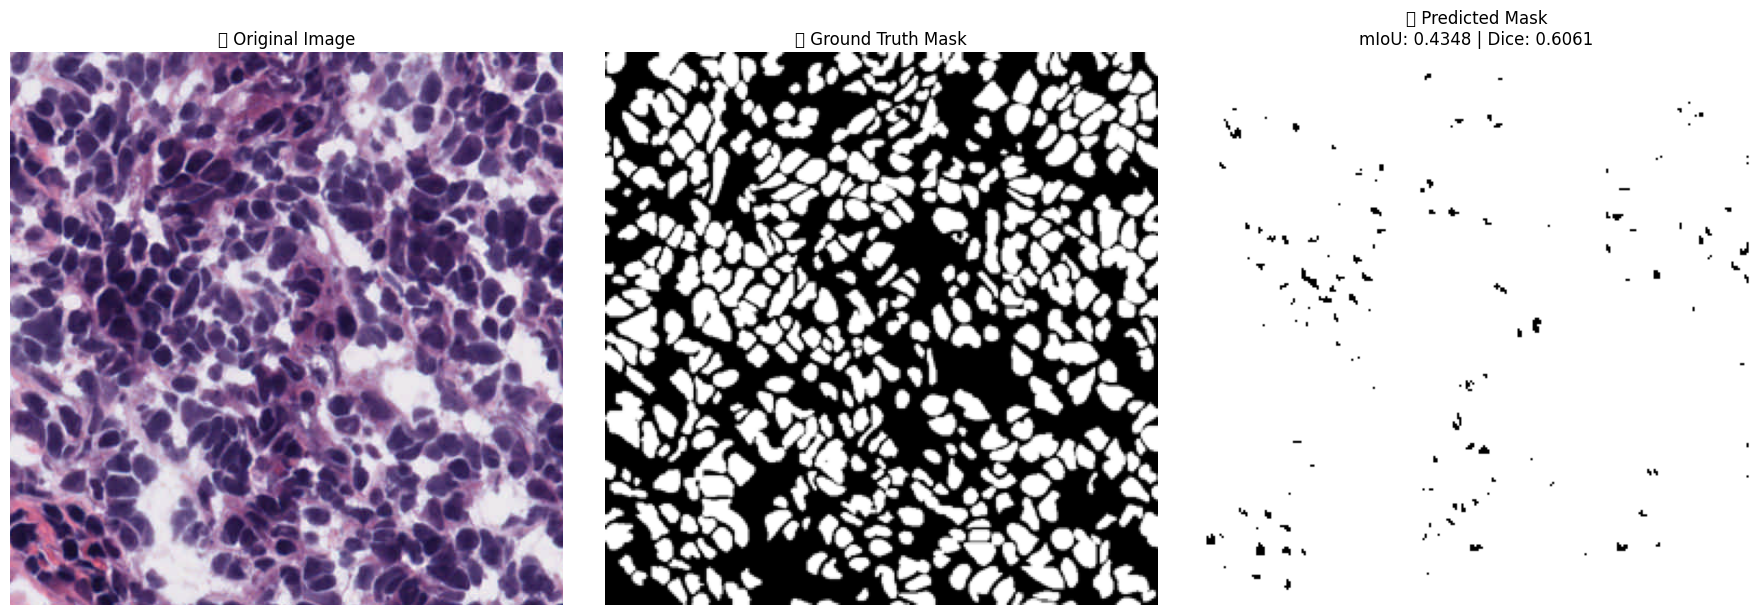

In [ ]:
# =================== UNET INFERENCE (KEEP ORIGINAL SIZE + METRICS + GT DISPLAY) ===================
from google.colab import files
import torch, numpy as np, cv2
from PIL import Image
import matplotlib.pyplot as plt

# ---- Step 1: Upload trained model ----
print("📂 Upload your trained model (.pth):")
uploaded_model = files.upload()
model_path = list(uploaded_model.keys())[0]
print(f"✅ Model uploaded: {model_path}")

# ---- Step 2: Define U-Net ----
class DoubleConv(torch.nn.Module):
    def __init__(self, in_c, out_c):
        super().__init__()
        self.conv = torch.nn.Sequential(
            torch.nn.Conv2d(in_c, out_c, 3, padding=1),
            torch.nn.BatchNorm2d(out_c),
            torch.nn.ReLU(inplace=True),
            torch.nn.Conv2d(out_c, out_c, 3, padding=1),
            torch.nn.BatchNorm2d(out_c),
            torch.nn.ReLU(inplace=True)
        )
    def forward(self, x):
        return self.conv(x)

class UNet(torch.nn.Module):
    def __init__(self, in_ch=3, out_ch=1, base=32):
        super().__init__()
        self.enc1 = DoubleConv(in_ch, base)
        self.enc2 = DoubleConv(base, base*2)
        self.enc3 = DoubleConv(base*2, base*4)
        self.enc4 = DoubleConv(base*4, base*8)
        self.center = DoubleConv(base*8, base*16)
        self.pool = torch.nn.MaxPool2d(2)
        self.up = torch.nn.Upsample(scale_factor=2, mode='bilinear', align_corners=True)
        self.dec4 = DoubleConv(base*16 + base*8, base*8)
        self.dec3 = DoubleConv(base*8 + base*4, base*4)
        self.dec2 = DoubleConv(base*4 + base*2, base*2)
        self.dec1 = DoubleConv(base*2 + base, base)
        self.final = torch.nn.Conv2d(base, out_ch, 1)
    def forward(self, x):
        e1 = self.enc1(x)
        e2 = self.enc2(self.pool(e1))
        e3 = self.enc3(self.pool(e2))
        e4 = self.enc4(self.pool(e3))
        c  = self.center(self.pool(e4))
        d4 = self.dec4(torch.cat([self.up(c), e4], dim=1))
        d3 = self.dec3(torch.cat([self.up(d4), e3], dim=1))
        d2 = self.dec2(torch.cat([self.up(d3), e2], dim=1))
        d1 = self.dec1(torch.cat([self.up(d2), e1], dim=1))
        return self.final(d1)

# ---- Step 3: Load model ----
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
model = UNet()
model.load_state_dict(torch.load(model_path, map_location=device))
model.to(device).eval()
print("✅ Model loaded successfully!")

# ---- Step 4: Upload test image ----
print("\n🖼️ Upload a .tif or .png test image:")
uploaded_img = files.upload()
img_path = list(uploaded_img.keys())[0]
print(f"✅ Using: {img_path}")

# ---- Step 5: Load original image ----
img_orig = Image.open(img_path).convert('RGB')
orig_w, orig_h = img_orig.size

# ---- Step 6: Resize for model input ----
img_resized = img_orig.resize((256,256))
img_np = np.array(img_resized).astype('float32') / 255.0
img_tensor = torch.tensor(img_np.transpose(2,0,1)).unsqueeze(0).to(device)

# ---- Step 7: Predict ----
with torch.no_grad():
    pred = model(img_tensor)
mask = torch.sigmoid(pred)[0,0].cpu().numpy()

# ---- Step 8: Convert to binary mask ----
mask_bin_256 = (mask > 0.5).astype(np.uint8) * 255
mask_bin_orig = cv2.resize(mask_bin_256, (orig_w, orig_h), interpolation=cv2.INTER_NEAREST)

# ---- Step 9: Save masks ----
cv2.imwrite("pred_mask_256.png", mask_bin_256)
cv2.imwrite("pred_mask_original_size.png", mask_bin_orig)
print("✅ Saved: pred_mask_256.png and pred_mask_original_size.png")

# ---- Step 10: Upload Ground Truth Mask ----
print("\n📁 Upload ground truth mask (same image) to compute metrics:")
uploaded_gt = files.upload()
gt_path = list(uploaded_gt.keys())[0]
gt_mask = Image.open(gt_path).convert('L')
gt_mask_resized = gt_mask.resize((256,256))
gt_np = np.array(gt_mask_resized).astype('float32') / 255.0

# ---- Step 11: Define Metric Functions ----
def iou_pytorch(preds, labels, smooth=1e-6):
    preds = torch.tensor(preds).unsqueeze(0)
    labels = torch.tensor(labels).unsqueeze(0)
    preds = (preds > 0.5).float()
    labels = (labels > 0.5).float()
    intersection = (preds * labels).sum()
    union = preds.sum() + labels.sum() - intersection
    return ((intersection + smooth) / (union + smooth)).item()

def dice_pytorch(preds, labels, smooth=1e-6):
    preds = torch.tensor(preds).unsqueeze(0)
    labels = torch.tensor(labels).unsqueeze(0)
    preds = (preds > 0.5).float()
    labels = (labels > 0.5).float()
    intersection = (preds * labels).sum()
    return ((2 * intersection + smooth) / (preds.sum() + labels.sum() + smooth)).item()

# ---- Step 12: Compute Metrics ----
mIoU = iou_pytorch(mask, gt_np)
dice = dice_pytorch(mask, gt_np)

print(f"\n📊 Evaluation Metrics (Resized to 256x256):")
print(f"   • Mean IoU  : {mIoU:.4f}")
print(f"   • Dice (F1) : {dice:.4f}")

# ---- Step 13: Display (NO OVERLAY) ----
plt.figure(figsize=(18,6))

plt.subplot(1,3,1)
plt.imshow(img_orig)
plt.title("🩸 Original Image")
plt.axis('off')

plt.subplot(1,3,2)
plt.imshow(gt_np, cmap='gray')
plt.title("🎯 Ground Truth Mask")
plt.axis('off')

plt.subplot(1,3,3)
plt.imshow(mask_bin_256, cmap='gray')
plt.title(f"🧠 Predicted Mask\nmIoU: {mIoU:.4f} | Dice: {dice:.4f}")
plt.axis('off')

plt.tight_layout()
plt.show()
# =================== END ===================


In [ ]:
!ls "/content/drive/MyDrive/unet_project/dataset/Annotator 1 (biologist)/distance maps" | head -n 10


Human_AdrenalGland_01.png
Human_AdrenalGland_02.png
Human_AdrenalGland_03.png
Human_Larynx_01.png
Human_Larynx_02.png
Human_Larynx_03.png
Human_LymphNodes_01.png
Human_LymphNodes_02.png
Human_LymphNodes_03.png
Human_Mediastinum_01.png
